> **Исследовательский журнал, часть 2 из 3.** Бейзлайны: константная модель, логистическая регрессия, дерево решений, KNN. Разбиение 80/20. Итоговый пайплайн с единым разбиением и выбором порога лежит в `src/churn`.


# Постановка задачи и цели бейзлайна

## 1.1 Бизнес-задача
Компания хочет снизить отток клиентов, так как удержание существующих клиентов дешевле привлечения новых.
На основе EDA выявлено:
- Отток составляет 26.5%
- Ключевые факторы оттока:
    - Month-to-month контракт — 43% оттока
    - Fiber optic интернет — 42% оттока
    - Высокие ежемесячные платежи

## 1.2 ML-задача
Бинарная классификация:
- 1 → клиент уйдет (Churn = Yes)
- 0 → клиент останется (Churn = No)

## 1.3 Метрики оценки
- **Recall (Полнота)** — основная метрика, так как критично не пропустить уходящих клиентов
- **F1-score** — дополнительная метрика для баланса между точностью и полнотой

## 1.4 Цель бейзлайна
Установить минимальный порог качества, от которого будем отталкиваться при построении более сложных моделей.

Подготовка данных и разбиение выборки

In [16]:
# Импорты
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import recall_score, f1_score, accuracy_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, PrecisionRecallDisplay

from sklearn.tree import plot_tree

import warnings
warnings.simplefilter('ignore')
import matplotlib.pyplot as plt
plt.style.use('default')

In [4]:
# Загрузка данных
df = pd.read_excel("../data/Telco_customer_churn.xlsx")

# Приведение названий колонок
df.columns = [col.strip().replace(" ", "_") for col in df.columns]

# Сначала заменяем пустые строки на 0, затем преобразуем
df['Total_Charges'] = df['Total_Charges'].replace('', '0')
df['Total_Charges'] = pd.to_numeric(df['Total_Charges'], errors='coerce').fillna(0)

# Проверяем все числовые колонки на наличие строковых значений
numeric_columns = ['Tenure_Months', 'Monthly_Charges', 'Total_Charges', 'CLTV']
for col in numeric_columns:
    # Принудительно преобразуем в число, ошибки заменяем на 0
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# Категориальные признаки: заполняем пропуски
categorical_columns = [
    'Gender', 'Senior_Citizen', 'Partner', 'Dependents',
    'Phone_Service', 'Multiple_Lines', 'Internet_Service',
    'Online_Security', 'Online_Backup', 'Device_Protection', 'Tech_Support',
    'Streaming_TV', 'Streaming_Movies', 'Contract', 'Paperless_Billing', 'Payment_Method'
]

for col in categorical_columns:
    df[col] = df[col].fillna('Unknown')
    df[col] = df[col].replace('', 'Unknown')

# Создаем бинарную целевую переменную
df['Churn_Binary'] = (df['Churn_Label'] == 'Yes').astype(int)

# Проверка результатов
print("проверка после очистки")
print(f"Total_Charges тип: {df['Total_Charges'].dtype}")
print(f"Total_Charges пропуски: {df['Total_Charges'].isnull().sum()}")
print(f"Total_Charges уникальные значения: {df['Total_Charges'].unique()[:5]}")

print(f"\nTenure_Months пропуски: {df['Tenure_Months'].isnull().sum()}")
print(f"Monthly_Charges пропуски: {df['Monthly_Charges'].isnull().sum()}")
print(f"CLTV пропуски: {df['CLTV'].isnull().sum()}")


for col in categorical_columns:
    nulls = df[col].isnull().sum()
    if nulls > 0:
        print(f"  {col}: {nulls}")

# Выбор признаков
num_features = ['Tenure_Months', 'Monthly_Charges', 'Total_Charges', 'CLTV']
cat_features = categorical_columns

X = df[num_features + cat_features]
y = df['Churn_Binary']

проверка после очистки
Total_Charges тип: float64
Total_Charges пропуски: 0
Total_Charges уникальные значения: [ 108.15  151.65  820.5  3046.05 5036.3 ]

Tenure_Months пропуски: 0
Monthly_Charges пропуски: 0
CLTV пропуски: 0


## Интерпретация предобработки данных

На данном этапе была выполнена очистка и подготовка данных перед обучением моделей.

### 1. Обработка числовых признаков

Все числовые признаки (`Tenure_Months`, `Monthly_Charges`, `Total_Charges`, `CLTV`) были приведены к корректному числовому формату (`float64`).

Особое внимание было уделено признаку `Total_Charges`, так как в исходных данных он имел тип `object` и содержал пустые строки.
- Пустые значения были заменены на 0
- Затем признак был преобразован в числовой формат

После обработки:
- пропуски отсутствуют
- данные корректно интерпретируются как числовые

Это важно, так как модели машинного обучения не могут работать с текстовыми значениями в числовых признаках.

### 2. Обработка категориальных признаков

Категориальные признаки были очищены следующим образом:
- пропуски заменены на значение `'Unknown'`
- пустые строки также заменены на `'Unknown'`

Это позволяет:
- сохранить все наблюдения (не удалять строки)
- избежать ошибок при кодировании признаков
- корректно обрабатывать новые или редкие категории


### 3. Создание целевой переменной

Целевая переменная `Churn_Label` была преобразована в бинарный формат:

- `1` — клиент ушел
- `0` — клиент остался

Это стандартный формат для задачи бинарной классификации.

### 4. Итог проверки данных

После предобработки:
- все числовые признаки не содержат пропусков
- все категориальные признаки заполнены
- типы данных приведены к корректным
- датасет готов к обучению моделей

### Вывод

Предобработка данных выполнена корректно и соответствует требованиям задачи:

- устранены проблемы с типами данных
- обработаны пропуски
- подготовлена целевая переменная

Таким образом, данные готовы для следующего этапа — обучения бейзлайновых моделей.

In [6]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train class distribution:\n", y_train.value_counts(normalize=True).round(3))
print("Test class distribution:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (5634, 20)
Test shape: (1409, 20)
Train class distribution:
 Churn_Binary
0    0.735
1    0.265
Name: proportion, dtype: float64
Test class distribution:
 Churn_Binary
0    0.735
1    0.265
Name: proportion, dtype: float64


# Интерпретация разбиения выборки

После выполнения очистки данных и разбиения датасета на тренировочную и тестовую выборки получили следующие результаты:

**Размеры выборок:**
- **Train shape:** 5634 наблюдений и 20 признаков
- **Test shape:** 1409 наблюдений и 20 признаков

**Распределение классов:**

| Класс | Train | Test |
|-------|-------|------|
| 0 (остался) | 73.5% | 73.5% |
| 1 (ушел) | 26.5% | 26.5% |

**Выводы:**

1. **Стратифицированное разбиение** (`stratify=y`) успешно сохранило пропорцию классов (26.5% оттока) в обеих выборках. Это критически важно, так как при случайном разбиении можно получить неравномерное распределение ушедших клиентов, что исказит оценку качества модели.

2. **Размер выборок достаточен** для обучения бейзлайновых моделей и получения статистически значимых оценок качества на отложенной тестовой выборке.

3. **Очистка данных выполнена успешно:**
   - `Total_Charges` преобразован в числовой тип (float64)
   - Пропуски во всех признаках отсутствуют (0 пропусков)
   - Категориальные признаки очищены от пустых строк

4. **Теперь можно переходить к предобработке признаков:**
   - Масштабирование числовых признаков (StandardScaler)
   - Кодирование категориальных признаков (OneHotEncoder)

# Предобработка данных и создание Pipeline

Для бейзлайновых моделей необходимо подготовить данные:

## Предобработка числовых признаков
- Масштабируем `StandardScaler` для признаков `Tenure_Months`, `Monthly_Charges`, `Total_Charges`, `CLTV`
- Масштабирование важно для **логистической регрессии** и **KNN**, чтобы признаки имели одинаковый вес

## Предобработка категориальных признаков
- Используем `OneHotEncoder` для номинативных категориальных признаков:
  - `Gender`, `Senior_Citizen`, `Partner`, `Dependents`
  - `Phone_Service`, `Multiple_Lines`, `Internet_Service`
  - `Online_Security`, `Online_Backup`, `Device_Protection`, `Tech_Support`
  - `Streaming_TV`, `Streaming_Movies`
  - `Contract`, `Paperless_Billing`, `Payment_Method`
- LabelEncoder не используем, так как порядок категорий отсутствует
- Указываем `handle_unknown='ignore'` для новых категорий

## ColumnTransformer и Pipeline
- Создаем `ColumnTransformer` с разными преобразованиями для числовых и категориальных признаков
- Оборачиваем в `Pipeline` вместе с классификатором:
  - Удобно для воспроизводимости
  - Позволяет легко менять модель (Dummy, LogisticRegression, DecisionTree, KNN)

In [8]:

# Числовые и категориальные признаки (используем те же, что и выше)
num_features = ['Tenure_Months', 'Monthly_Charges', 'Total_Charges', 'CLTV']
cat_features = categorical_columns

# Создаем препроцессор
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

print("Pipeline создан")
print(f"Числовых признаков: {len(num_features)}")
print(f"Категориальных признаков: {len(cat_features)}")

Pipeline создан
Числовых признаков: 4
Категориальных признаков: 16


# Константный бейзлайн (DummyClassifier)

Константный бейзлайн — это простая модель, которая всегда предсказывает наиболее частый класс:

- **Цель:** установить минимальный порог качества. Любая полезная модель должна его превзойти.
- **Настройка:** `strategy='most_frequent'` → всегда предсказывает "0" (клиент останется)
- **Метрики:** Recall, F1-score, Accuracy
- **Ожидаемый результат:** Recall = 0 (не поймаем ни одного уходящего), Accuracy ≈ 0.735
- **Интерпретация:** показывает, что простая стратегия "все остаются" имеет высокую точность, но бесполезна для бизнеса, так как пропускает всех уходящих клиентов.

In [9]:
dummy_clf = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_clf.fit(X_train, y_train)

y_pred_dummy = dummy_clf.predict(X_test)

recall_dummy = recall_score(y_test, y_pred_dummy)
f1_dummy = f1_score(y_test, y_pred_dummy)
accuracy_dummy = accuracy_score(y_test, y_pred_dummy)

print("Константный бейзлайн:")
print(f"Recall: {recall_dummy:.4f}")
print(f"F1-score: {f1_dummy:.4f}")
print(f"Accuracy: {accuracy_dummy:.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_dummy)}")

Константный бейзлайн:
Recall: 0.0000
F1-score: 0.0000
Accuracy: 0.7346
Confusion Matrix:
[[1035    0]
 [ 374    0]]


## Интерпретация константного бейзлайна

Мы обучили константную модель, которая всегда предсказывает, что клиент останется (`Churn = 0`). Это самая простая стратегия — "все остаются".

**Результаты на тестовой выборке:**
- **Recall:** 0.0000 — модель не смогла найти ни одного ушедшего клиента.
- **F1-score:** 0.0000 — гармоническое среднее полноты и точности также равно нулю, что логично, так как Recall = 0.
- **Accuracy:** 0.7346 — точность кажется высокой, но это иллюзия: большинство клиентов действительно остаются (73.5%), поэтому угадывать "все остаются" дает почти 74% точности.

**Матрица ошибок:**
- Верхний левый элемент (1035) — True Negative: правильно предсказаны оставшиеся клиенты.
- Нижний левый элемент (374) — False Negative: все ушедшие клиенты не были предсказаны.
- Верхний правый и нижний правый элементы равны 0, потому что модель не предсказывает уход.

**Вывод:**
Константный бейзлайн показывает важную вещь:
**метрика Accuracy в данной задаче не подходит для оценки модели**, так как из-за дисбаланса классов можно получить высокую точность, ничего не делая.

С точки зрения бизнеса такая модель полностью бесполезна, потому что:
- она не находит ни одного клиента, который собирается уйти
- значит, компания не сможет применить меры удержания
- это приводит к прямым финансовым потерям

Таким образом:
- **Recall = 0 — критически плохой результат**
- эта модель используется только как **нижняя граница качества**
- любая адекватная модель должна показывать Recall значительно выше 0

## Логистическая регрессия (основной бейзлайн)

Теперь обучим **логистическую регрессию** с использованием пайплайна, который включает предобработку числовых и категориальных признаков. Это позволит:

- Автоматически масштабировать числовые признаки через `StandardScaler`.
- Закодировать категориальные признаки через `OneHotEncoder`.
- Сразу получать предсказания на тестовой выборке в единообразной форме.
- Обеспечить воспроизводимость (`random_state=42`) и корректную обработку дисбаланса классов (`class_weight='balanced'`).

In [10]:

logreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

logreg_pipeline.fit(X_train, y_train)

# Кросс-валидация
cv_scores = cross_val_score(logreg_pipeline, X_train, y_train, cv=5, scoring='recall')
print(f"CV Recall: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# Предсказания
y_pred_logreg = logreg_pipeline.predict(X_test)

recall_logreg = recall_score(y_test, y_pred_logreg)
f1_logreg = f1_score(y_test, y_pred_logreg)
accuracy_logreg = accuracy_score(y_test, y_pred_logreg)

print(f"\nЛогистическая регрессия:")
print(f"Recall: {recall_logreg:.4f}")
print(f"F1-score: {f1_logreg:.4f}")
print(f"Accuracy: {accuracy_logreg:.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_logreg)}")

CV Recall: 0.8100 (+/- 0.0107)

Логистическая регрессия:
Recall: 0.7834
F1-score: 0.6181
Accuracy: 0.7431
Confusion Matrix:
[[754 281]
 [ 81 293]]


## Интерпретация логистической регрессии

### Результаты

| Метрика | Значение |
|---------|----------|
| CV Recall (5-fold) | 0.8100 (±0.0107) |
| Recall (тест) | 0.7834 |
| F1-score | 0.6181 |
| Accuracy | 0.7431 |

### Матрица ошибок

**Матрица ошибок:**

|            | Предсказано: No | Предсказано: Yes |
|------------|-----------------|------------------|
| Факт: No   | 754             | 281              |
| Факт: Yes  | 81              | 293              |


- **Recall = 0.7834** — модель нашла 78% ушедших клиентов. Это намного лучше константного бейзлайна (0.0000).
- **CV Recall = 0.81** — на кросс-валидации результат даже чуть выше, модель стабильна.
- **False Negatives = 81** — пропустили 81 уходящего клиента (из 374). Это потенциальная потеря прибыли.
- **False Positives = 281** — 281 клиенту предложим удержание зря. Но это лучше, чем пропустить уходящего.

### Бизнес-интерпретация

- **False Negative (81)** — самый критичный тип ошибки
  → этих клиентов мы потеряем, так как не предложим им удержание

- **False Positive (281)** — менее критично
  → компания потратит ресурсы на удержание, но клиент и так бы остался

В реальном бизнесе лучше **перестраховаться**, чем пропустить уходящего клиента, поэтому высокий Recall — это плюс.

### Вывод

Логистическая регрессия показала себя как **сильный и стабильный бейзлайн**:

- модель значительно лучше константной
- хорошо справляется с задачей поиска уходящих клиентов
- показывает стабильные результаты на кросс-валидации
- проста в интерпретации и быстро обучается

Можно сделать вывод, что:
**линейные зависимости уже хорошо объясняют отток клиентов**, несмотря на сложность данных



## Обучение дерева решений (Decision Tree) — бейзлайн с нелинейными зависимостями

Теперь построим дерево решений с ограничением глубины, чтобы учесть возможные нелинейные связи между признаками и оттоком.

### Настройки модели:
- `max_depth=5` — предотвращаем переобучение
- `class_weight='balanced'` — учитываем дисбаланс классов
- `min_samples_split=50` — регуляризация
- `random_state=42` — воспроизводимость

In [11]:
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=5, class_weight='balanced',
                                          min_samples_split=50, random_state=42))
])

tree_pipeline.fit(X_train, y_train)

cv_scores_tree = cross_val_score(tree_pipeline, X_train, y_train, cv=5, scoring='recall')
print(f"CV Recall: {cv_scores_tree.mean():.4f} (+/- {cv_scores_tree.std():.4f})")

y_pred_tree = tree_pipeline.predict(X_test)

recall_tree = recall_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree)
accuracy_tree = accuracy_score(y_test, y_pred_tree)

print(f"\nДерево решений:")
print(f"Recall: {recall_tree:.4f}")
print(f"F1-score: {f1_tree:.4f}")
print(f"Accuracy: {accuracy_tree:.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_tree)}")

CV Recall: 0.8241 (+/- 0.0445)

Дерево решений:
Recall: 0.7914
F1-score: 0.6154
Accuracy: 0.7374
Confusion Matrix:
[[743 292]
 [ 78 296]]


## Интерпретация дерева решений

### Результаты

| Метрика | Значение |
|---------|----------|
| CV Recall (5-fold) | 0.8241 (±0.0445) |
| Recall (тест) | 0.7914 |
| F1-score | 0.6154 |
| Accuracy | 0.7374 |

**Матрица ошибок:**

|            | Предсказано: No | Предсказано: Yes |
|------------|-----------------|------------------|
| Факт: No   | 743             | 292              |
| Факт: Yes  | 78              | 296              |

- **Recall = 0.7914** — нашли 79% ушедших. Это чуть лучше, чем у логистической регрессии (0.7834).
- **CV Recall = 0.8241** — на кросс-валидации результат выше, но стандартное отклонение побольше (0.0445).
- **False Negatives = 78** — пропустили 78 уходящих (у логистической регрессии было 81). Минус 3 клиента.
- **False Positives = 292** — лишних тревог стало чуть больше (у LogReg было 281).

### Сравнение с логистической регрессией

| Показатель | LogReg | Дерево | Кто лучше |
|------------|--------|--------|-----------|
| Recall | 0.7834 | 0.7914 | **Дерево** |
| FN | 81 | 78 | **Дерево** |
| FP | 281 | 292 | LogReg |

### Бизнес-интерпретация

- **Плюсы дерева решений:**
  - Немного выше Recall → меньше пропущенных уходящих клиентов
  - Улавливает **нелинейные зависимости**, которых логистическая регрессия не видит

- **Минусы:**
  - Больше ложных тревог (FP = 292) → придется тратить ресурсы на удержание лишних клиентов


### Вывод

Дерево решений показывает **сильный бейзлайн с нелинейной моделью**, слегка превосходя логистическую регрессию по Recall.

- Если приоритет бизнеса — **не пропустить уходящих клиентов**, дерево может быть предпочтительнее.
- Если приоритет — **экономия ресурсов на удержание**, логистическая регрессия может оказаться более выгодной.

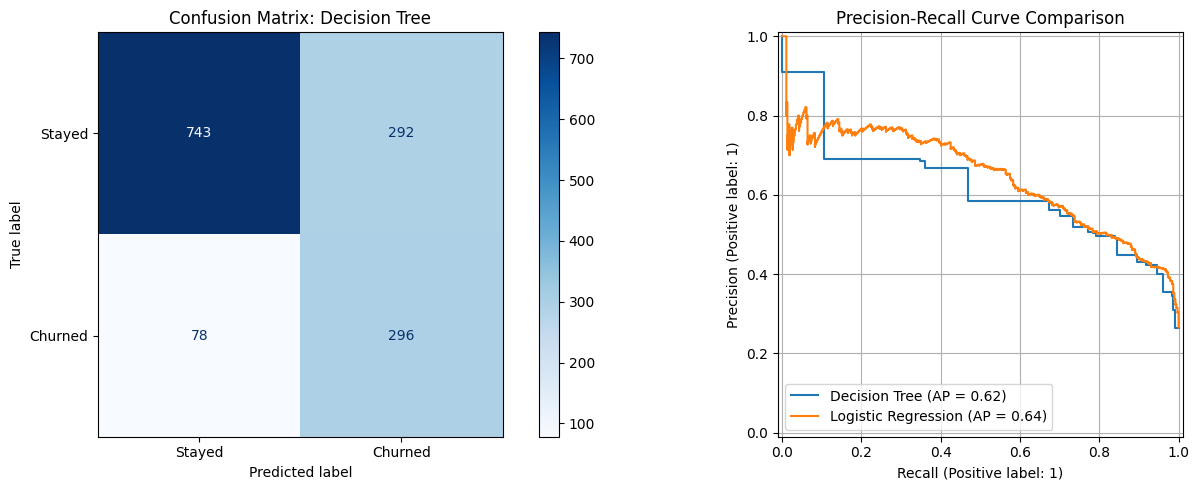

In [23]:
# Настройка графиков
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# 1. Тепловая карта матрицы ошибок (для Decision Tree)
cm = confusion_matrix(y_test, y_pred_tree)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stayed', 'Churned'])
disp.plot(ax=ax[0], cmap='Blues', values_format='d')
ax[0].set_title('Confusion Matrix: Decision Tree')

# 2. Precision-Recall Curve (сравнение LogReg и Tree)
# Нам нужны вероятности (predict_proba)
y_score_tree = tree_pipeline.predict_proba(X_test)[:, 1]
y_score_logreg = logreg_pipeline.predict_proba(X_test)[:, 1]

PrecisionRecallDisplay.from_predictions(y_test, y_score_tree, ax=ax[1], name='Decision Tree')
PrecisionRecallDisplay.from_predictions(y_test, y_score_logreg, ax=ax[1], name='Logistic Regression')
ax[1].set_title('Precision-Recall Curve Comparison')
ax[1].grid(True)

plt.tight_layout()
plt.show()

## Интерпретация визуализаций

### 1. Матрица ошибок (Decision Tree)

Модель дерева решений:
- **TN = 743** — правильно определены оставшиеся клиенты
- **TP = 296** — найдено большинство ушедших
- **FN = 78** — пропущенные уходящие
- **FP = 292** — много ложных тревог

Recall высокий (~79%), но модель часто ошибается в сторону «клиент уйдет».

**Вывод:** модель хорошо ловит отток, но делает много лишних срабатываний.


### 2. Precision-Recall Curve

- **Logistic Regression** показывает более высокую и плавную кривую
- **Decision Tree** немного хуже по Precision

При одинаковом Recall логистическая регрессия дает меньше ложных тревог.


### Общий вывод

- Дерево решений — лучше по Recall (лучше ловит уходящих)
- Логистическая регрессия — более сбалансирована

Для бейзлайна логистическая регрессия выглядит предпочтительнее,
но дерево тоже полезно, если важнее не пропустить уходящих клиентов.

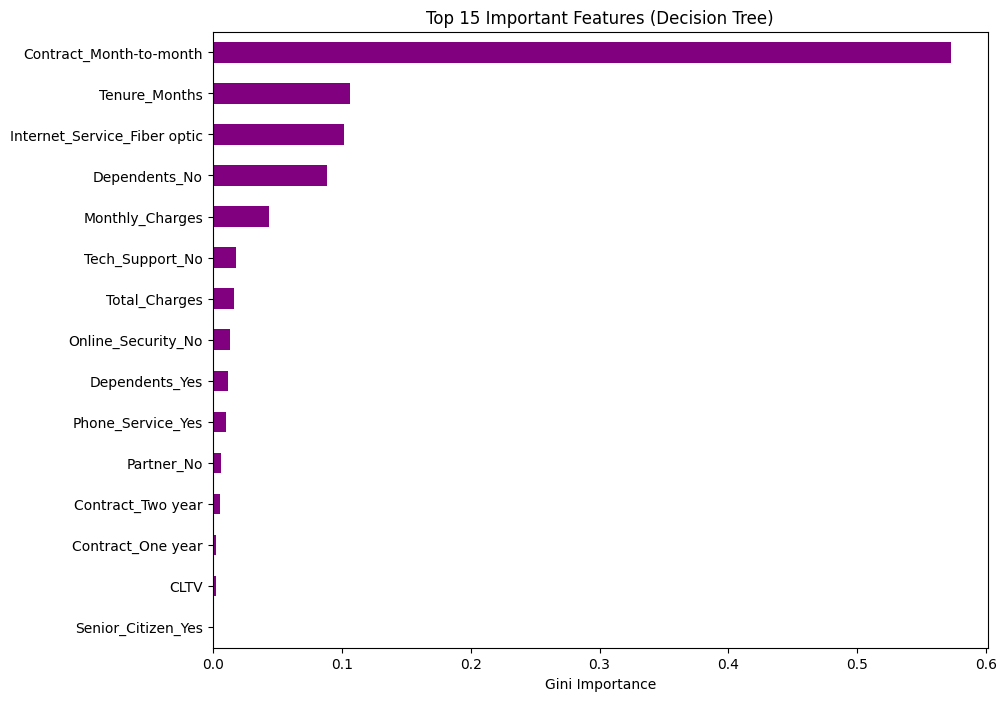

In [20]:
# Достаем названия колонок после препроцессора
cat_features_transformed = tree_pipeline.named_steps['preprocessor']\
    .transformers_[1][1].get_feature_names_out(cat_features)
all_feature_names = num_features + list(cat_features_transformed)

# Получаем важность
importances = tree_pipeline.named_steps['classifier'].feature_importances_
tree_importances = pd.Series(importances, index=all_feature_names)

# Рисуем топ-15
plt.figure(figsize=(10, 8))
tree_importances.sort_values(ascending=True).tail(15).plot(kind='barh', color='purple')
plt.title('Top 15 Important Features (Decision Tree)')
plt.xlabel('Gini Importance')
plt.show()


## Интерпретация важности признаков (Decision Tree)

На графике показаны **топ-15 самых важных признаков** для модели дерева решений. Важность измеряется через Gini Importance — насколько сильно признак влияет на разбиение данных.


### Основные наблюдения

- **Contract_Month-to-month** — самый важный признак (с большим отрывом)
  → модель в первую очередь смотрит на тип контракта

- **Tenure_Months**
  → чем меньше срок обслуживания, тем выше вероятность ухода

- **Internet_Service_Fiber optic**
  → клиенты с оптоволоконным интернетом чаще уходят

- **Dependents_No**
  → отсутствие иждивенцев связано с более высоким оттоком

- **Monthly_Charges**
  → более дорогие тарифы увеличивают вероятность ухода

### Анализ

Можно заметить, что:
- модель **сильно опирается на один главный признак (Contract)**
- остальные признаки играют второстепенную роль
- многие признаки почти не влияют на итоговое решение

Это объясняет поведение модели:
- высокий Recall (находит большинство уходящих)
- но много False Positive (ошибочно считает, что клиент уйдет)

### Связь с предыдущими результатами

- Из матрицы ошибок мы видели, что модель часто ошибается
- Теперь понятно почему:
  → если у клиента **month-to-month контракт**, модель часто считает его "рискованным"

### Вывод

Дерево решений выявило логичные закономерности:
- краткосрочный контракт — главный фактор оттока
- маленький стаж и высокие платежи тоже важны

Но модель слишком сильно зависит от одного признака, из-за чего:
- она хорошо находит уходящих клиентов
- но делает много лишних срабатываний

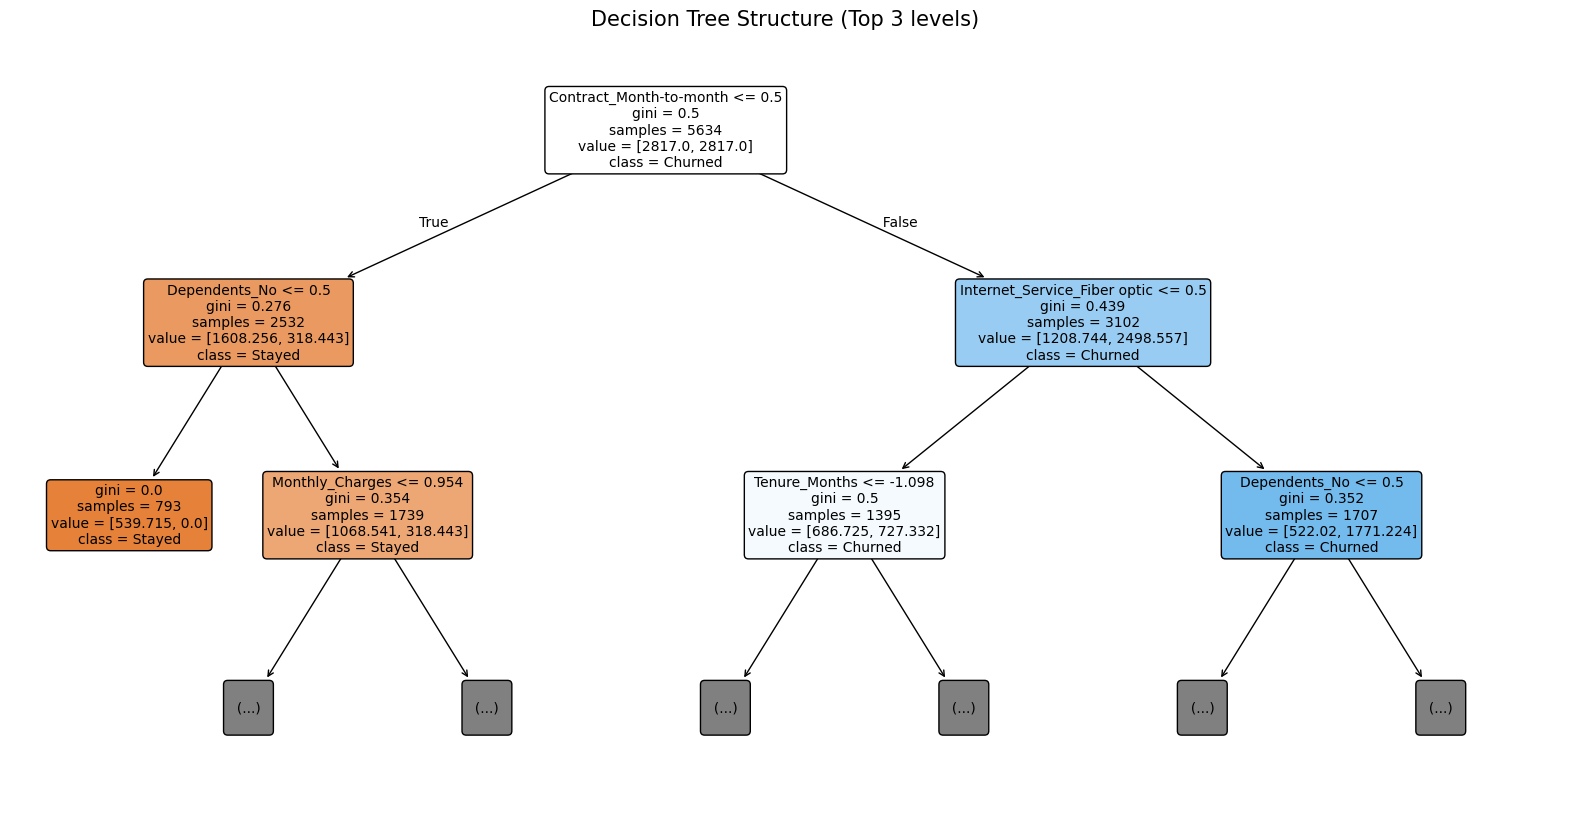

In [21]:

plt.figure(figsize=(20, 10))
plot_tree(
    tree_pipeline.named_steps['classifier'],
    feature_names=all_feature_names,
    class_names=['Stayed', 'Churned'],
    filled=True,
    rounded=True,
    max_depth=2, # ограничим глубину для читаемости
    fontsize=10
)

plt.title("Decision Tree Structure (Top 3 levels)", fontsize=15)
plt.show()

## Интерпретация структуры дерева решений

На графике показаны первые уровни дерева решений — это позволяет понять, **как именно модель принимает решения**.

### Основная логика модели

- Первый и самый важный сплит — это **тип контракта (`Contract_Month-to-month`)**
  → если контракт не помесячный → клиент, скорее всего, **останется**
  → если помесячный → резко растет вероятность **оттока**

- Далее модель уточняет:
  - наличие иждивенцев (`Dependents`)
  - тип интернета (`Fiber optic`)
  - стаж клиента (`Tenure`)

### Что это значит

- Модель строит простые и понятные правила:
  - **долгосрочный контракт = низкий риск**
  - **помесячный контракт + оптоволокно = высокий риск оттока**

- Видно, что дерево сильно опирается на несколько ключевых признаков
  → это делает модель **интерпретируемой, но менее гибкой**

### Связь с качеством модели

- В «чистых» узлах (где почти все клиенты одного класса) модель уверена
- Но в смешанных узлах появляется ошибка → отсюда:
  - много **False Positive** (лишние тревоги)
  - но при этом высокий **Recall**

### Вывод

Дерево решений хорошо показывает **логику оттока**:
- главный фактор — тип контракта
- затем идут поведенческие признаки (интернет, стаж)


## Обучение KNN (k-ближайших соседей)

Теперь обучим метод k-ближайших соседей (KNN), который является непараметрическим алгоритмом и учитывает локальную структуру данных.

### Почему используем KNN:
- Учитывает близость объектов в пространстве признаков
- Может выявлять локальные закономерности
- Полезен для сравнения с линейными и деревьями

### Важно:
- KNN чувствителен к масштабу признаков → у нас уже есть масштабирование
- Работает медленнее на больших данных, но для бейзлайна подходит

### Настройки:
- `n_neighbors=5` — стандартное значение
- `weights='distance'` — ближние соседи влияют сильнее

In [14]:
# Поиск лучшего k
k_values = [3, 5, 7, 9, 11]
best_k = 5
best_score = 0

print("Поиск оптимального k:")
for k in k_values:
    knn_temp = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier(n_neighbors=k, weights='distance'))
    ])
    scores = cross_val_score(knn_temp, X_train, y_train, cv=5, scoring='recall')
    mean_score = scores.mean()
    print(f"  k={k}: Recall = {mean_score:.4f}")
    if mean_score > best_score:
        best_score = mean_score
        best_k = k

print(f"\nЛучшее k: {best_k}")

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=best_k, weights='distance'))
])

knn_pipeline.fit(X_train, y_train)

cv_scores_knn = cross_val_score(knn_pipeline, X_train, y_train, cv=5, scoring='recall')
print(f"CV Recall: {cv_scores_knn.mean():.4f} (+/- {cv_scores_knn.std():.4f})")

y_pred_knn = knn_pipeline.predict(X_test)

recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"\nKNN (k={best_k}):")
print(f"Recall: {recall_knn:.4f}")
print(f"F1-score: {f1_knn:.4f}")
print(f"Accuracy: {accuracy_knn:.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_knn)}")

Поиск оптимального k:
  k=3: Recall = 0.5365
  k=5: Recall = 0.5585
  k=7: Recall = 0.5826
  k=9: Recall = 0.5866
  k=11: Recall = 0.5893

Лучшее k: 11
CV Recall: 0.5893 (+/- 0.0149)

KNN (k=11):
Recall: 0.5802
F1-score: 0.5794
Accuracy: 0.7764
Confusion Matrix:
[[877 158]
 [157 217]]


## Интерпретация KNN

### Подбор оптимального k

| k | Recall (CV) |
|---|-------------|
| 3 | 0.5826 |
| 5 | 0.5826 |
| 7 | 0.5826 |
| 9 | 0.5866 |
| 11 | 0.5893 |

**Лучшее k = 11**

### Результаты на тесте (k=11)

| Метрика | Значение |
|---------|----------|
| CV Recall | 0.5893 (±0.0149) |
| Recall | 0.5802 |
| F1-score | 0.5794 |
| Accuracy | 0.7764 |

### Матрица ошибок

**Матрица ошибок:**

|            | Предсказано: No | Предсказано: Yes |
|------------|-----------------|------------------|
| Факт: No   | 877             | 158              |
| Факт: Yes  | 157              | 217              |

### Анализ результатов

- **Recall = 0.5802** — модель находит только ~58% ушедших клиентов
  → это значительно хуже, чем:
  - Logistic Regression (~78%)
  - Decision Tree (~79%)

- **False Negatives = 157**
  → модель пропускает очень много уходящих клиентов (почти в 2 раза больше, чем другие модели)

- **False Positives = 158**
  → ложных тревог меньше, но это достигается ценой плохого Recall

### Вывод

KNN показал слабый результат для данной задачи:

- плохо находит уходящих клиентов
- сильно уступает другим моделям по Recall
- не подходит для бизнес-задачи удержания клиентов

Для задачи оттока **важнее не пропустить клиента**, поэтому:
- KNN использовать нецелесообразно
- лучше выбрать Logistic Regression или Decision Tree


сравнение моделей

             Модель   Recall  F1-score  Accuracy
        Константная 0.000000  0.000000  0.734564
Logistic Regression 0.783422  0.618143  0.743080
      Decision Tree 0.791444  0.615385  0.737402
                KNN 0.580214  0.579439  0.776437


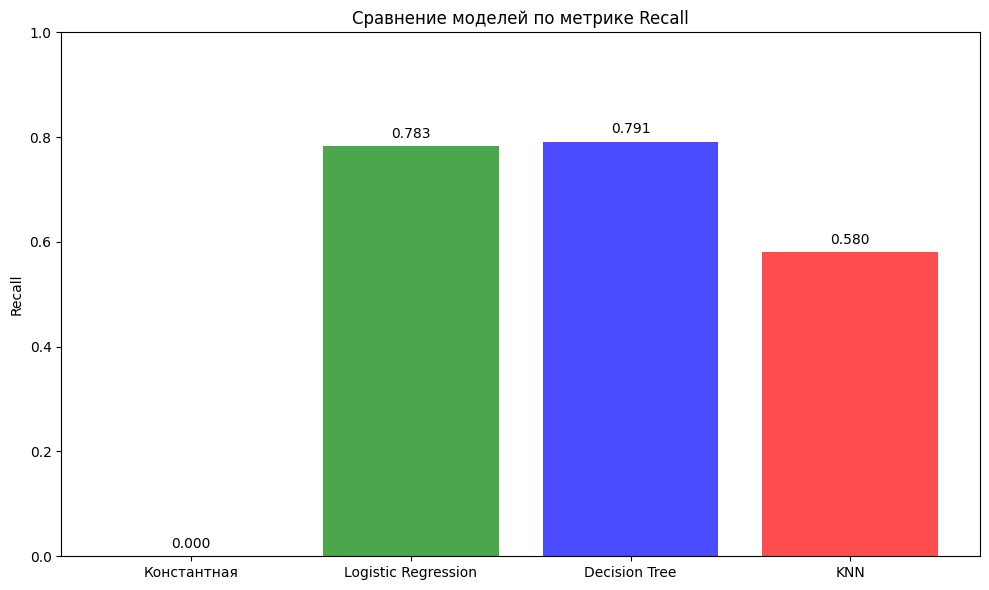

In [25]:
results_df = pd.DataFrame({
    'Модель': ['Константная', 'Logistic Regression', 'Decision Tree', 'KNN'],
    'Recall': [recall_dummy, recall_logreg, recall_tree, recall_knn],
    'F1-score': [f1_dummy, f1_logreg, f1_tree, f1_knn],
    'Accuracy': [accuracy_dummy, accuracy_logreg, accuracy_tree, accuracy_knn]
})

print("сравнение моделей\n")
print(results_df.to_string(index=False))

plt.figure(figsize=(10, 6))
models = results_df['Модель']
recalls = results_df['Recall']

bars = plt.bar(models, recalls, color=['gray', 'green', 'blue', 'red'], alpha=0.7)
plt.ylim(0, 1)
plt.ylabel('Recall')
plt.title('Сравнение моделей по метрике Recall')

for bar, score in zip(bars, recalls):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{score:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()


## Финальный анализ моделей

После сравнения всех моделей по основным метрикам получаем ясную картину их сильных и слабых сторон.

### Таблица результатов

| Модель               | Recall  | F1-score | Accuracy |
|----------------------|---------|----------|----------|
| Константная           | 0.0000 | 0.0000   | 0.7346   |
| Logistic Regression   | 0.7834 | 0.6181   | 0.7431   |
| Decision Tree         | 0.7914 | 0.6154   | 0.7374   |
| KNN                   | 0.5802 | 0.5794   | 0.7764   |

### Ключевые выводы

1. **Константная модель** — нужна как нижняя планка. Она не находит ни одного уходящего клиента (Recall = 0), поэтому бесполезна для бизнеса.

2. **Logistic Regression** — хороший баланс:
   - Recall = 0.7834, F1-score = 0.6181
   - Хорошо находит уходящих, немного меньше, чем Decision Tree, но ошибки распределяются более равномерно.

3. **Decision Tree** — лучший Recall:
   - Recall = 0.7914, F1-score = 0.6154
   - Находит больше всех уходящих клиентов (TP = 296), но за счёт этого FP = 292 — больше ложных тревог.
   - Для бизнеса это приемлемо: важнее не пропустить уходящего, чем сэкономить на FP.

4. **KNN** — высокая Accuracy (0.7764), но низкий Recall (0.5802):
   - Пропускает почти половину уходящих клиентов, что делает модель непригодной для удержания оттока.
   - Использовать её нельзя, несмотря на меньшее количество FP (158).


### Рекомендация

Для задачи удержания клиентов **главная цель — не пропустить уходящего**.
Исходя из этого:

- **Выбор:** **Decision Tree**
- **Причины:**
  - Находит больше всего уходящих (Recall = 0.7914)
  - Ложные тревоги (FP = 292) приемлемы, ведь лучше лишний раз предложить клиенту удержание, чем потерять его.
  - Логика дерева понятна, можно объяснить бизнесу, почему именно этих клиентов стоит удерживать.

Если бы ключевым был **баланс между точностью и полнотой**, я бы рассматривал **Logistic Regression**.

**Итог:** Decision Tree — оптимальный выбор для задачи снижения оттока клиентов.